In [1]:
import pandas as pd

In [2]:
import numpy as np

In [3]:
df = pd.read_csv("/content/archive(3).zip")

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.naive_bayes import GaussianNB
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

In [6]:
# The CSV file should be in the same folder as this notebook.
columns = [
    'Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness',
    'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome'
]

df.head()

,6,148,72,35,0,33.6,0.627,50,1
0,1,85,66,29,0,26.6,0.351,31,0
1,8,183,64,0,0,23.3,0.672,32,1
2,1,89,66,23,94,28.1,0.167,21,0
3,0,137,40,35,168,43.1,2.288,33,1
4,5,116,74,0,0,25.6,0.201,30,0


In [8]:
print("Dataset shape:", df.shape)
print("\\nMissing values:")
print(df.isnull().sum())
print("\\nOutcome counts:")


Dataset shape: (767, 9)
\nMissing values:
6        0
148      0
72       0
35       0
0        0
33.6     0
0.627    0
50       0
1        0
dtype: int64
\nOutcome counts:


In [11]:
# Assign the correct column names first
df.columns = columns

# Separate input features (X) and target (y)
X = df.drop("Outcome", axis=1)
y = df['Outcome']

# Split data so the model is evaluated on data it did not train on.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

model = GaussianNB()
model.fit(X_train, y_train)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

Training rows: 613
Testing rows: 154


In [12]:
# Example input: [Pregnancies, Glucose, BloodPressure, SkinThickness,
#                 Insulin, BMI, DiabetesPedigreeFunction, Age]
test = [
    [2, 120, 70, 25, 80, 28.5, 0.30,  30],
    [6, 148, 72, 35, 0, 33.6, 0.627, 50]
]

print("-- Prediction ----------------------------")
for t in test:
    row = pd.DataFrame([t], columns=X.columns)
    pred = model.predict(row)[0]
    prob = model.predict_proba(row)[0]
    result = "Diabetes" if pred == 1 else "No diabetes"

    print("\\nInput:", dict(zip(X.columns, t)))
    print("Result:", result)
    print(f"P(No diabetes) = {prob[0]:.4f}")
    print(f"P(Diabetes)     = {prob[1]:.4f}")

-- Prediction ----------------------------
\nInput: {'Pregnancies': 2, 'Glucose': 120, 'BloodPressure': 70, 'SkinThickness': 25, 'Insulin': 80, 'BMI': 28.5, 'DiabetesPedigreeFunction': 0.3, 'Age': 30}
Result: No diabetes
P(No diabetes) = 0.9594
P(Diabetes)     = 0.0406
\nInput: {'Pregnancies': 6, 'Glucose': 148, 'BloodPressure': 72, 'SkinThickness': 35, 'Insulin': 0, 'BMI': 33.6, 'DiabetesPedigreeFunction': 0.627, 'Age': 50}
Result: Diabetes
P(No diabetes) = 0.3524
P(Diabetes)     = 0.6476


In [13]:
y_pred = model.predict(X_test)
print(f"Test Accuracy: {accuracy_score(y_test, y_pred) * 100:.2f}%")
print("\\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=['No diabetes', 'Diabetes']))

Test Accuracy: 66.88%
\nClassification Report:
              precision    recall  f1-score   support

 No diabetes       0.74      0.75      0.75       100
    Diabetes       0.53      0.52      0.52        54

    accuracy                           0.67       154
   macro avg       0.64      0.63      0.63       154
weighted avg       0.67      0.67      0.67       154



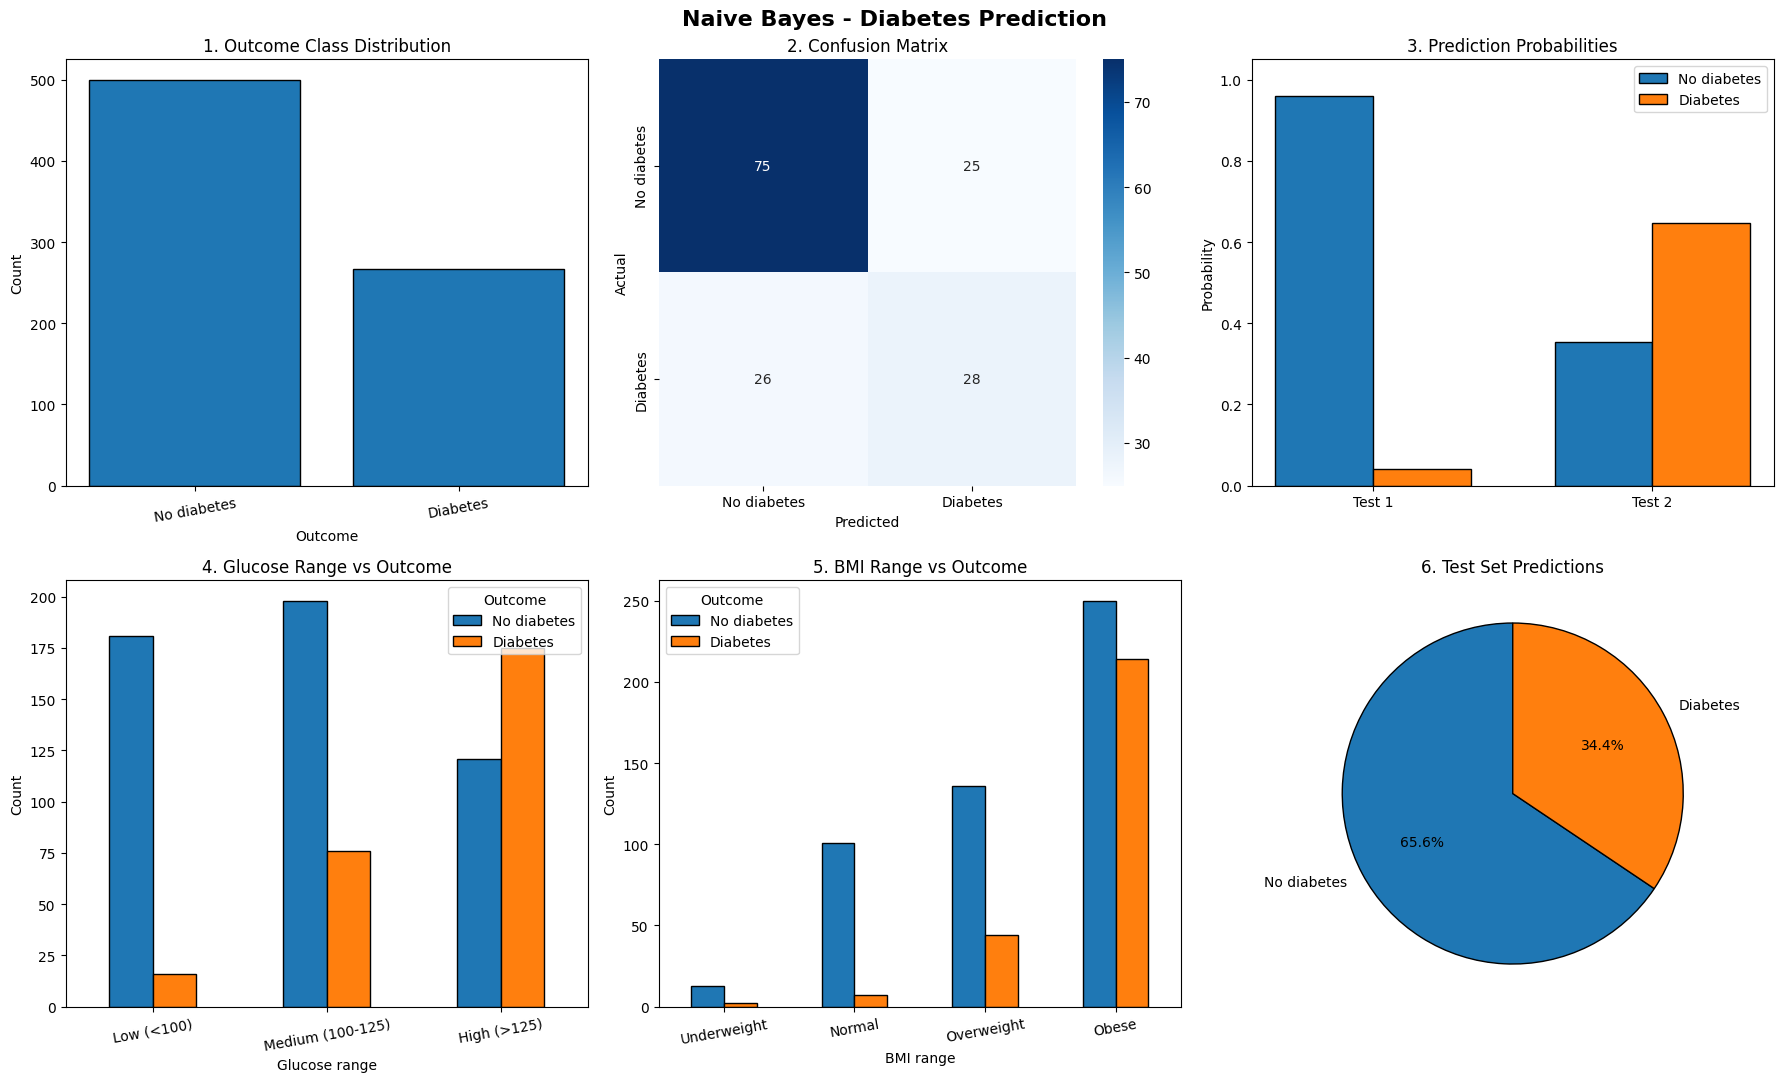

In [14]:
# Predictions for the held-out test set
y_pred = model.predict(X_test)

fig, axes = plt.subplots(2, 3, figsize=(18, 11))
fig.suptitle("Naive Bayes - Diabetes Prediction", fontsize=16, fontweight="bold")

# 1. Class distribution
counts = df['Outcome'].map({0: 'No diabetes', 1: 'Diabetes'}).value_counts()
axes[0, 0].bar(counts.index, counts.values, edgecolor='black')
axes[0, 0].set_title("1. Outcome Class Distribution")
axes[0, 0].set_xlabel("Outcome")
axes[0, 0].set_ylabel("Count")
axes[0, 0].tick_params(axis='x', rotation=10)

# 2. Confusion matrix
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, cmap='Blues', fmt='g',
            xticklabels=['No diabetes', 'Diabetes'],
            yticklabels=['No diabetes', 'Diabetes'], ax=axes[0, 1])
axes[0, 1].set_title("2. Confusion Matrix")
axes[0, 1].set_xlabel("Predicted")
axes[0, 1].set_ylabel("Actual")

# 3. Prediction probabilities for example records
test_df = pd.DataFrame(test, columns=X.columns)
test_probs = model.predict_proba(test_df)
labels = [f"Test {i+1}" for i in range(len(test))]
pos = np.arange(len(labels))
width = 0.35
axes[0, 2].bar(pos - width/2, test_probs[:, 0], width, label='No diabetes', edgecolor='black')
axes[0, 2].bar(pos + width/2, test_probs[:, 1], width, label='Diabetes', edgecolor='black')
axes[0, 2].set_title("3. Prediction Probabilities")
axes[0, 2].set_xticks(pos)
axes[0, 2].set_xticklabels(labels)
axes[0, 2].set_ylim(0, 1.05)
axes[0, 2].set_ylabel("Probability")
axes[0, 2].legend()

# 4. Glucose range vs outcome
df['GlucoseRange'] = pd.cut(df['Glucose'], bins=[-1, 99, 125, 300],
                            labels=['Low (<100)', 'Medium (100-125)', 'High (>125)'])
glucose_counts = pd.crosstab(df['GlucoseRange'], df['Outcome']).reindex(
    ['Low (<100)', 'Medium (100-125)', 'High (>125)'], fill_value=0)
glucose_counts.columns = ['No diabetes', 'Diabetes']
glucose_counts.plot(kind='bar', ax=axes[1, 0], edgecolor='black', rot=10)
axes[1, 0].set_title("4. Glucose Range vs Outcome")
axes[1, 0].set_xlabel("Glucose range")
axes[1, 0].set_ylabel("Count")
axes[1, 0].legend(title="Outcome")

# 5. BMI range vs outcome
df['BMIRange'] = pd.cut(df['BMI'], bins=[-1, 18.5, 25, 30, 100],
                        labels=['Underweight', 'Normal', 'Overweight', 'Obese'])
bmi_counts = pd.crosstab(df['BMIRange'], df['Outcome'])
bmi_counts.columns = ['No diabetes', 'Diabetes']
bmi_counts.plot(kind='bar', ax=axes[1, 1], edgecolor='black', rot=10)
axes[1, 1].set_title("5. BMI Range vs Outcome")
axes[1, 1].set_xlabel("BMI range")
axes[1, 1].set_ylabel("Count")
axes[1, 1].legend(title="Outcome")

# 6. Pie chart of test-set predictions
pred_counts = pd.Series(y_pred).map({0: 'No diabetes', 1: 'Diabetes'}).value_counts()
axes[1, 2].pie(pred_counts, labels=pred_counts.index, autopct='%1.1f%%',
               startangle=90, wedgeprops={'edgecolor': 'black'})
axes[1, 2].set_title("6. Test Set Predictions")

plt.tight_layout()
plt.show()